# Проверка гипотезы: после первой наблюдаемой доставки с опозданием покупатели реже делают повторный заказ за 90 дней

In [7]:
from getpass import getpass
from sqlalchemy import URL, create_engine

connection_url = URL.create(
    drivername="postgresql+psycopg",
    username=input("Имя пользователя PostgreSQL: "),
    password=getpass("Пароль PostgreSQL: "),
    host="localhost",
    port=5432,
    database="olist_analytics",
)

engine = create_engine(connection_url)

In [8]:
import pandas as pd
from sqlalchemy import text

with engine.connect() as connection:
    cohorts = pd.read_sql_query(
        text("""
            SELECT *
            FROM mart.customer_cohorts
            ORDER BY cohort_month, is_late
        """),
        connection,
    )

cohorts.head(10)

,cohort_month,is_late,eligible_customers,repeat_customers,repeat_purchase_rate_90d_pct
0,2016-10-01,False,203,0,0.00
1,2016-11-01,False,55,0,0.00
2,2016-11-01,True,2,0,0.00
3,2016-12-01,False,3,1,33.33
4,2016-12-01,True,1,0,0.00
5,2017-01-01,False,263,2,0.76
6,2017-02-01,False,1324,13,0.98
7,2017-02-01,True,1,0,0.00
8,2017-03-01,False,2294,22,0.96
9,2017-03-01,True,50,1,2.00


In [9]:
repeat_stats = cohorts.groupby("is_late").agg(
    eligible_customers=("eligible_customers", "sum"),
    repeat_customers=("repeat_customers", "sum"),
)

repeat_stats["repeat_rate_pct"] = (
    repeat_stats["repeat_customers"]
    / repeat_stats["eligible_customers"]
    * 100
).round(2)

repeat_stats

,eligible_customers,repeat_customers,repeat_rate_pct
is_late,,,
False,68118,801,1.18
True,5221,41,0.79


Для неопоздавших доставок 1.18% потворных заказов в течении 90 дней, для опоздавших 0.79% 

In [16]:
per_month = cohorts.groupby(["cohort_month", "is_late"]).agg(
    eligible_customers=("eligible_customers", "sum"),
    repeat_customers=("repeat_customers", "sum"),
)
per_month["repeat_rate_pct"] = (
    per_month["repeat_customers"]
    / per_month["eligible_customers"]
    * 100
).round(2)

per_month

eligible_customers  repeat_customers  repeat_rate_pct
cohort_month is_late                                                       
2016-10-01   False                   203                 0             0.00
2016-11-01   False                    55                 0             0.00
             True                      2                 0             0.00
2016-12-01   False                     3                 1            33.33
             True                      1                 0             0.00
2017-01-01   False                   263                 2             0.76
2017-02-01   False                  1324                13             0.98
             True                      1                 0             0.00
2017-03-01   False                  2294                22             0.96
             True                     50                 1             2.00
2017-04-01   False                  1719                21             1.22
             True                     85                 0             0.00
2017-05-01   False                  3492                44             1.26
             True                    181                 2             1.10
2017-06-01   False                  3034                42             1.38
             True                     90                 1             1.11
2017-07-01   False                  3266                32             0.98
             True                     89                 2             2.25
2017-08-01   False                  4074                53             1.30
             True                     92                 0             0.00
2017-09-01   False                  3690                59             1.60
             True                    142                 1             0.70
2017-10-01   False                  4148                51             1.23
             True                    177                 3             1.69
2017-11-01   False                  4338                63             1.45
             True                    183                 2             1.09
2017-12-01   False                  6361                57             0.90
             True                    607                 6             0.99
2018-01-01   False                  5796                63             1.09
             True                    605                 2             0.33
2018-02-01   False                  5331                55             1.03
             True                    317                 3             0.95
2018-03-01   False                  5709                58             1.02
             True                    854                 5             0.59
2018-04-01   False                  6303                76             1.21
             True                   1288                 7             0.54
2018-05-01   False                  6471                84             1.30
             True                    408                 5             1.23
2018-06-01   False                   244                 5             2.05
             True                     49                 1             2.04

In [17]:
monthly_repeat_rates = per_month["repeat_rate_pct"].unstack("is_late")

monthly_repeat_rates

is_late,False,True
cohort_month,,
2016-10-01,0.00,NaN
2016-11-01,0.00,0.00
2016-12-01,33.33,0.00
2017-01-01,0.76,NaN
2017-02-01,0.98,0.00
2017-03-01,0.96,2.00
2017-04-01,1.22,0.00
2017-05-01,1.26,1.10
2017-06-01,1.38,1.11


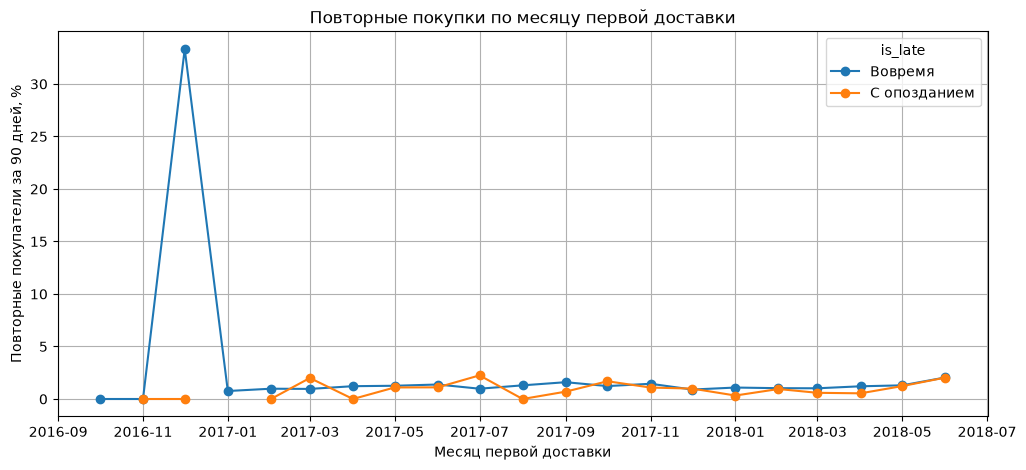

In [21]:
import matplotlib.pyplot as plt

monthly_repeat_rates = monthly_repeat_rates.rename(columns={False: "Вовремя", True: "С опозданием"})
ax = monthly_repeat_rates.plot(
    figsize=(12, 5),
    marker="o",
    ylabel="Повторные покупатели за 90 дней, %",
    xlabel="Месяц первой доставки",
    title="Повторные покупки по месяцу первой доставки",
    grid=True,
)

plt.show()

In [22]:
per_month[["eligible_customers", "repeat_customers"]]

eligible_customers  repeat_customers
cohort_month is_late                                      
2016-10-01   False                   203                 0
2016-11-01   False                    55                 0
             True                      2                 0
2016-12-01   False                     3                 1
             True                      1                 0
2017-01-01   False                   263                 2
2017-02-01   False                  1324                13
             True                      1                 0
2017-03-01   False                  2294                22
             True                     50                 1
2017-04-01   False                  1719                21
             True                     85                 0
2017-05-01   False                  3492                44
             True                    181                 2
2017-06-01   False                  3034                42
             True                     90                 1
2017-07-01   False                  3266                32
             True                     89                 2
2017-08-01   False                  4074                53
             True                     92                 0
2017-09-01   False                  3690                59
             True                    142                 1
2017-10-01   False                  4148                51
             True                    177                 3
2017-11-01   False                  4338                63
             True                    183                 2
2017-12-01   False                  6361                57
             True                    607                 6
2018-01-01   False                  5796                63
             True                    605                 2
2018-02-01   False                  5331                55
             True                    317                 3
2018-03-01   False                  5709                58
             True                    854                 5
2018-04-01   False                  6303                76
             True                   1288                 7
2018-05-01   False                  6471                84
             True                    408                 5
2018-06-01   False                   244                 5
             True                     49                 1

In [23]:
per_month["eligible_customers"].unstack("is_late")

is_late,False,True
cohort_month,,
2016-10-01,203.0,NaN
2016-11-01,55.0,2.0
2016-12-01,3.0,1.0
2017-01-01,263.0,NaN
2017-02-01,1324.0,1.0
2017-03-01,2294.0,50.0
2017-04-01,1719.0,85.0
2017-05-01,3492.0,181.0
2017-06-01,3034.0,90.0


## Выводы по 4-й гипотезе

Среди покупателей, получивших первую доставку вовремя, повторный заказ сделали 801 из 68 118 человек — 1,18%. После первой доставки с опозданием — 41 из 5 221 человека — 0,79%.

Доля повторных покупателей после опоздания ниже примерно на 0,39 процентного пункта. Общий результат согласуется с гипотезой. При этом месячная динамика неоднородна — в отдельных когортах доля после опоздания выше, чем после доставки вовремя.

Для бизнеса результат служит основанием проверить улучшение доставки в пилоте, измеряя и соблюдение сроков, и повторные покупки за одинаковое окно наблюдения.